In [217]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import Lasso, ElasticNet, Ridge
from sklearn.ensemble import GradientBoostingRegressor
import lightgbm as lgb
import xgboost as xgb


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv


In [218]:
train_data = pd.read_csv("/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv")
test_data = pd.read_csv("/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv")

# EDA


In [219]:
train_data.shape

(1460, 81)

In [220]:
col = train_data.isnull().sum()
col[col > 0].sort_values()

Electrical         1
MasVnrArea         8
BsmtCond          37
BsmtFinType1      37
BsmtQual          37
BsmtExposure      38
BsmtFinType2      38
GarageType        81
GarageQual        81
GarageFinish      81
GarageCond        81
GarageYrBlt       81
LotFrontage      259
FireplaceQu      690
MasVnrType       872
Fence           1179
Alley           1369
MiscFeature     1406
PoolQC          1453
dtype: int64

## Valuable Nan
PoolQC (1453) 

MiscFeature (1406)

Alley (1369)

Fence (1179)

FireplaceQu (690)

GarageType (81)

GarageFinish (81)

GarageQual (81)

GarageCond (81)

BsmtQual (37)

BsmtCond (37)

BsmtFinType1 (37)

BsmtExposure (38)

BsmtFinType2 (38)

In [221]:
train_data[:][["PoolQC", "Fence"]]

,PoolQC,Fence
0,NaN,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,NaN,NaN
...,...,...
1455,NaN,NaN
1456,NaN,MnPrv
1457,NaN,GdPrv
1458,NaN,NaN


In [222]:
for col in train_data.columns:
    top_ratio = train_data[col].value_counts(normalize=True).iloc[0]
    if top_ratio > 0.95:
        print(col, round(top_ratio * 100, 1), '%')

Street 99.6 %
Utilities 99.9 %
Condition2 99.0 %
RoofMatl 98.2 %
Heating 97.8 %
LowQualFinSF 98.2 %
KitchenAbvGr 95.3 %
GarageQual 95.1 %
GarageCond 96.2 %
3SsnPorch 98.4 %
PoolArea 99.5 %
MiscVal 96.4 %


Have

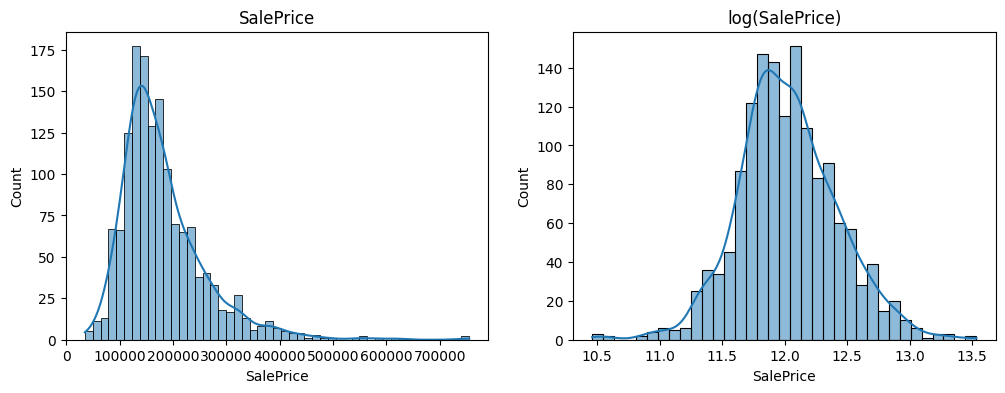

In [223]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_data['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('SalePrice')
sns.histplot(np.log1p(train_data['SalePrice']), kde=True, ax=axes[1])
axes[1].set_title('log(SalePrice)')
plt.show()



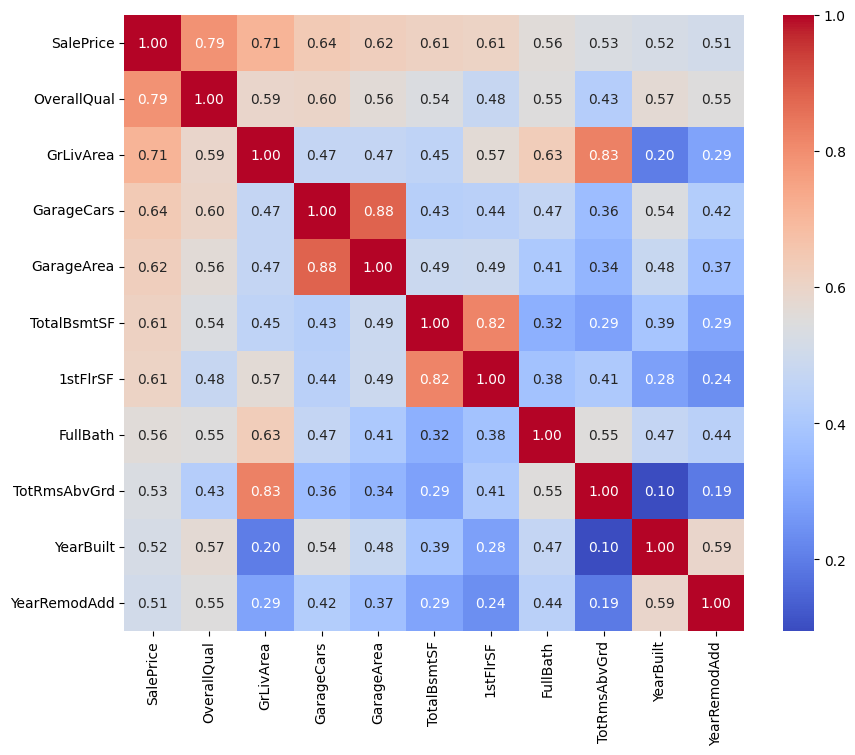

In [224]:
corr = train_data.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False)
top = corr.head(11).index

plt.figure(figsize=(10, 8))
sns.heatmap(train_data[top].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

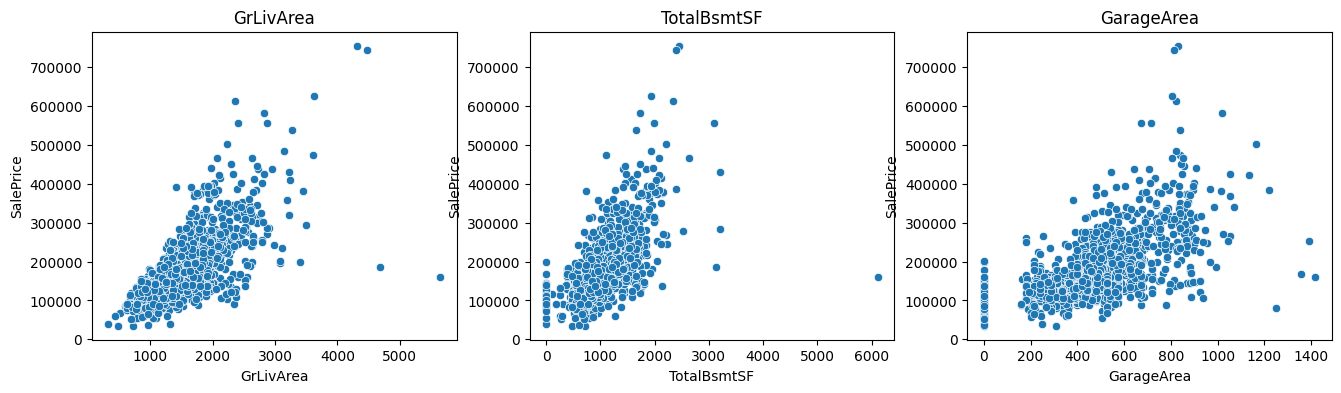

In [225]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['GrLivArea', 'TotalBsmtSF', 'GarageArea']):
    sns.scatterplot(x=train_data[col], y=train_data['SalePrice'], ax=ax)
    ax.set_title(col)
plt.show()

In [226]:
cat_cols = train_data.select_dtypes(include='object').columns
for col in cat_cols[:5]:
    print(train_data[col].value_counts())
    print()

MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64

Street
Pave    1454
Grvl       6
Name: count, dtype: int64

Alley
Grvl    50
Pave    41
Name: count, dtype: int64

LotShape
Reg    925
IR1    484
IR2     41
IR3     10
Name: count, dtype: int64

LandContour
Lvl    1311
Bnk      63
HLS      50
Low      36
Name: count, dtype: int64



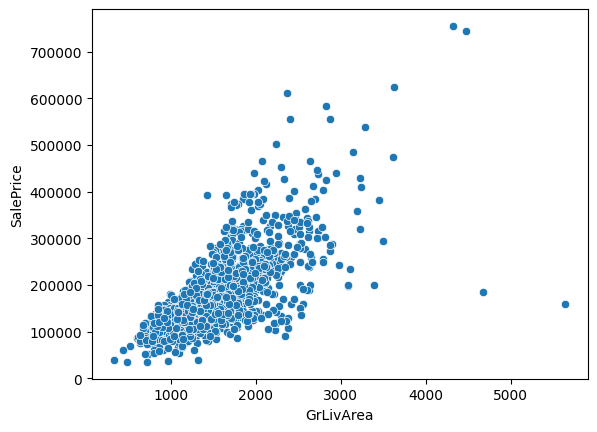

,Id,GrLivArea,SalePrice
523,524,4676,184750
1298,1299,5642,160000


In [227]:
sns.scatterplot(x='GrLivArea', y='SalePrice', data=train_data)
plt.show()

train_data[(train_data['GrLivArea'] > 4000) & (train_data['SalePrice'] < 300000)][['Id', 'GrLivArea', 'SalePrice']]

# Cleaning



In [228]:
train_data = train_data[ ~( (train_data["GrLivArea"] > 4000) & (train_data["SalePrice"] < 300000) ) ]

In [229]:
y = np.log1p(train_data['SalePrice'])



In [230]:
test_id = test_data["Id"]
n_train = len(train_data)


In [231]:
df = pd.concat([train_data.drop(columns=["SalePrice"]), test_data], ignore_index=True)
df = df.drop(columns=["Id"])

# Fill missing values


**Nan meaning dont have**

In [232]:
none_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
             "BsmtFinType2", "MasVnrType"]

for i in none_cols:
    df[i] = df[i].fillna("None")

**Nan meaning dont have but in number cols**

In [233]:
zero_cols = ["GarageArea", "GarageCars", "BsmtFinSF1",
             "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF", "BsmtFullBath",
             "BsmtHalfBath", "MasVnrArea"]

for i in zero_cols:
    df[i] = df[i].fillna(0)


In [234]:
df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(
    lambda s: s.fillna(s.median()))


In [235]:
for c in df.columns:
    if df[c].isna().any():
        if df[c].dtype == "object":
            df[c] = df[c].fillna(df[c].mode()[0])
        else:
            df[c] = df[c].fillna(df[c].median())

In [236]:
for c in ["MSSubClass", "YrSold", "MoSold"]:
    df[c] = df[c].astype(str)


**Encoding quality cols**

In [237]:
qual = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
for c in ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
          "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]:
    df[c] = df[c].map(qual).astype(int)


In [238]:
ordmap = {
    "BsmtExposure": {"None":0,"No":1,"Mn":2,"Av":3,"Gd":4},
    "BsmtFinType1": {"None":0,"Unf":1,"LwQ":2,"Rec":3,"BLQ":4,"ALQ":5,"GLQ":6},
    "BsmtFinType2": {"None":0,"Unf":1,"LwQ":2,"Rec":3,"BLQ":4,"ALQ":5,"GLQ":6},
    "GarageFinish": {"None":0,"Unf":1,"RFn":2,"Fin":3},
    "Functional":   {"Sal":0,"Sev":1,"Maj2":2,"Maj1":3,"Mod":4,"Min2":5,"Min1":6,"Typ":7},
    "LotShape":     {"IR3":0,"IR2":1,"IR1":2,"Reg":3},
    "LandSlope":    {"Sev":0,"Mod":1,"Gtl":2},
    "PavedDrive":   {"N":0,"P":1,"Y":2},
    "CentralAir":   {"N":0,"Y":1},
}
for c, m in ordmap.items():
    df[c] = df[c].map(m).astype(int)

# Feature Engineering


In [239]:

df["TotalBath"] = (df["FullBath"] + 0.5 * df["HalfBath"]
                   + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"])

df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
df["TotalPorchSF"] = (df["OpenPorchSF"] + df["EnclosedPorch"]
                      + df["3SsnPorch"] + df["ScreenPorch"] + df["WoodDeckSF"])
df["QualSF"] = df["OverallQual"] * df["TotalSF"]

df["RemodAge"] = df["YearRemodAdd"].max() - df["YearRemodAdd"]
df["HouseAge"] = df["YearBuilt"].max() - df["YearBuilt"]
#Has function
df["HasPool"] = (df["PoolArea"] > 0).astype(int)
df["Has2ndFloor"] = (df["2ndFlrSF"] > 0).astype(int)
df["HasGarage"] = (df["GarageArea"] > 0).astype(int)
df["HasBsmt"] = (df["TotalBsmtSF"] > 0).astype(int)
df["HasFireplace"] = (df["Fireplaces"] > 0).astype(int)

df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YearBuilt"])

In [240]:
num_cols = df.select_dtypes(include=[np.number]).columns
skewed = df[num_cols].apply(lambda s: skew(s)).abs()
for c in skewed[skewed > 0.75].index:
    df[c] = np.log1p(df[c].clip(lower=0))
 


In [241]:
df = pd.get_dummies(df, drop_first=True)
keep = (df.iloc[:n_train] != 0).sum() >= 10
df = df.loc[:, keep]

X = df.iloc[:n_train].values
X_test = df.iloc[n_train:].values
print("Shape:", X.shape, X_test.shape)


Shape: (1458, 242) (1459, 242)


# model comparison

kf = KFold(5, shuffle=True, random_state=42)
 
def rmse_cv(model):
    s = cross_val_score(model, X, y, scoring="neg_mean_squared_error", cv=kf)
    return np.sqrt(-s)
 
models = {
    "lasso": make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=20000)),
    "enet":  make_pipeline(RobustScaler(),
                           ElasticNet(alpha=0.0005, l1_ratio=0.9, max_iter=20000)),
    "ridge": make_pipeline(RobustScaler(), Ridge(alpha=10)),
    "gbr":   GradientBoostingRegressor(n_estimators=2000, learning_rate=0.02,
                                       max_depth=4, max_features="sqrt",
                                       min_samples_leaf=15, min_samples_split=10,
                                       loss="huber", subsample=0.8,
                                       random_state=42),
    "lgbm":  lgb.LGBMRegressor(n_estimators=2500, learning_rate=0.01,
                               num_leaves=6, max_bin=200, subsample=0.7,
                               subsample_freq=1, colsample_bytree=0.3,
                               random_state=42, verbose=-1),
    "xgb":   xgb.XGBRegressor(n_estimators=2500, learning_rate=0.01,
                              max_depth=3, subsample=0.7,
                              colsample_bytree=0.4, random_state=42,
                              n_jobs=-1),
}
 
scores = {}
for name, m in models.items():
    s = rmse_cv(m)
    scores[name] = s.mean()
    print(f"{name:6s} RMSE(log) = {s.mean():.5f} +- {s.std():.5f}")
 


from sklearn.model_selection import cross_val_predict

oof = {n: cross_val_predict(m, X, y, cv=kf) for n, m in models.items()}

def rmse(p): return np.sqrt(np.mean((y - p) ** 2))

blend = np.mean([oof[n] for n in ["lasso", "gbr", "xgb", "lgbm"]], axis=0)
print("Blend:", rmse(blend))

In [242]:
kf = KFold(5, shuffle=True, random_state=42)

models = {
    "lasso": make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=20000)),
    "gbr":   GradientBoostingRegressor(n_estimators=2000, learning_rate=0.02,
                                       max_depth=4, max_features="sqrt",
                                       min_samples_leaf=15, min_samples_split=10,
                                       loss="huber", subsample=0.8,
                                       random_state=42),
}

In [243]:
models["lasso"].fit(X, y)
models["gbr"].fit(X, y)
pred_log = 0.5 * models["lasso"].predict(X_test) + 0.5 * models["gbr"].predict(X_test)
pred = np.expm1(pred_log)

sub = pd.DataFrame({"Id": test_id, "SalePrice": pred})
sub.to_csv("submission.csv", index=False)
print("Your submission was successfully saved!")

Your submission was successfully saved!
